In [3]:
from datasets import get_dataset_config_names, get_dataset_split_names, load_dataset

dataset = load_dataset("nyu-planet-finders/kepler-raw-lightcurves",split="full",streaming=True)
print(dataset)

lightcurves = load_dataset("nyu-planet-finders/kepler-raw-lightcurves","lightcurves",split="full",streaming=True,)
print(lightcurves)

tces = load_dataset("nyu-planet-finders/kepler-raw-lightcurves","tces",split="full",streaming=True,)
print(tces)

IterableDataset({
    features: ['kepid', 'quarter', 'source_filename', 'source_relpath', 'source_uri', 'source_size_bytes', 'sha256', 'row_count', 'tstart', 'tstop', 'bjdref', 'time_unit', 'time_system', 'ra', 'dec', 'kepmag', 'module', 'output', 'channel', 'data_release', 'time', 'cadenceno', 'sap_flux', 'sap_flux_err', 'pdcsap_flux', 'pdcsap_flux_err', 'sap_quality'],
    num_shards: 40
})
IterableDataset({
    features: ['kepid', 'quarter', 'source_filename', 'source_relpath', 'source_uri', 'source_size_bytes', 'sha256', 'row_count', 'tstart', 'tstop', 'bjdref', 'time_unit', 'time_system', 'ra', 'dec', 'kepmag', 'module', 'output', 'channel', 'data_release', 'time', 'cadenceno', 'sap_flux', 'sap_flux_err', 'pdcsap_flux', 'pdcsap_flux_err', 'sap_quality'],
    num_shards: 40
})
IterableDataset({
    features: ['rowid', 'kepid', 'tce_plnt_num', 'av_training_set', 'av_pred_class', 'tce_period', 'tce_time0bk', 'tce_duration', 'tce_depth', 'tce_model_snr', 'tce_max_mult_ev', 'tce_impact

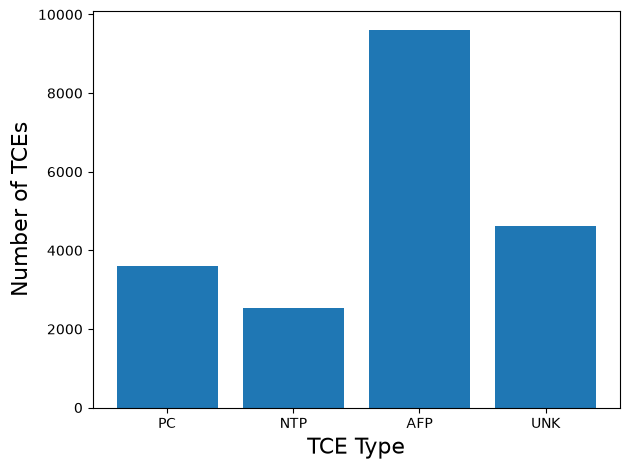

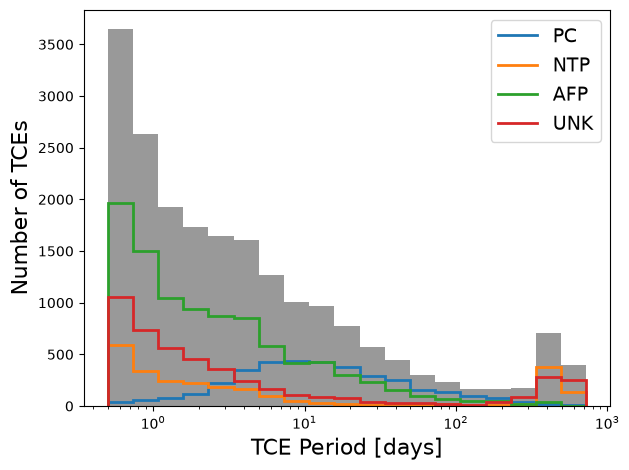

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
# Keep only the columns needed for the plots.
df = pd.DataFrame({"label": row["av_training_set"],"period": row["tce_period"],}for row in tces)

labels = df["label"].unique()
counts_for_label = []
for label in labels:
    counts_for_label.append(len(df[df["label"]==label]))

plt.bar(labels, counts_for_label)
plt.xlabel("TCE Type", fontsize=16)
plt.ylabel("Number of TCEs", fontsize=16)
plt.tight_layout()
plt.savefig("tce_type_bar_plot.pdf")
plt.show()

# Histogram: distribution of numeric TCE periods.
bins = 10**np.linspace(np.log10(np.min(df["period"])), np.log10(np.max(df["period"])), 20)

vals, bins = np.histogram(df["period"], bins=bins)
plt.stairs(vals, bins, fill=True, color="black", alpha=0.4)
for label in labels:
    subdf = df[df["label"]==label]
    vals, bins = np.histogram(subdf["period"], bins=bins)
    plt.stairs(vals, bins, fill=False, label=label, lw=2)
plt.xscale("log")
plt.xlabel("TCE Period [days]", fontsize=16)
plt.ylabel("Number of TCEs", fontsize=16)
plt.legend(fontsize=14)
plt.tight_layout()
plt.savefig("tce_period_histogram.pdf")
plt.show()


dict_keys(['kepid', 'quarter', 'source_filename', 'source_relpath', 'source_uri', 'source_size_bytes', 'sha256', 'row_count', 'tstart', 'tstop', 'bjdref', 'time_unit', 'time_system', 'ra', 'dec', 'kepmag', 'module', 'output', 'channel', 'data_release', 'time', 'cadenceno', 'sap_flux', 'sap_flux_err', 'pdcsap_flux', 'pdcsap_flux_err', 'sap_quality'])



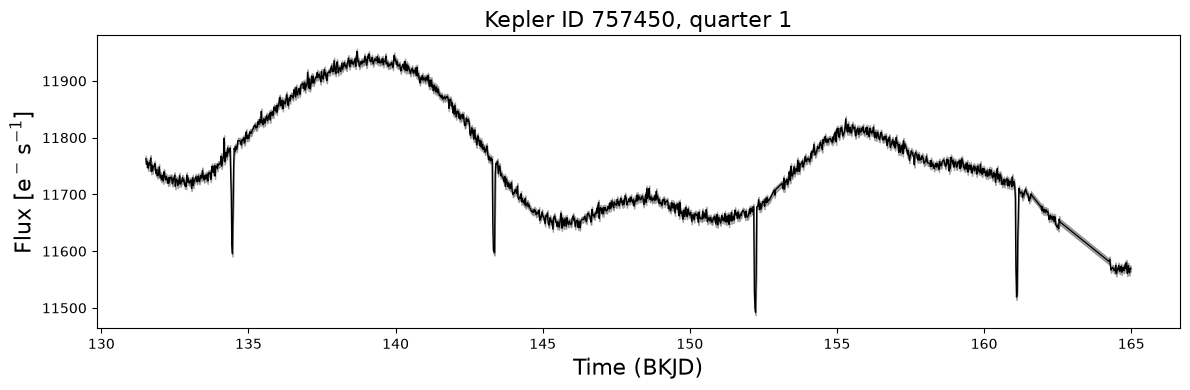

In [37]:
import matplotlib.pyplot as plt
from itertools import islice

# Get the first 3 rows from the streaming dataset
samples = list(islice(lightcurves, 0,1))
print(samples[0].keys())

print()
fig, axes = plt.subplots(len(samples), 1, figsize=(12, 4))

# Make axes iterable if there is only one sample
if len(samples) == 1:
    axes = [axes]

for ax, row in zip(axes, samples):
    time = np.array(row["time"])
    flux = np.array(row["pdcsap_flux"])
    flux_err = np.array(row["pdcsap_flux_err"])
    quality = np.array(row["sap_quality"])
    
    good = (quality == 0) & np.isfinite(flux) # quality is 0 when there's no problem
    ax.plot(time[good], flux[good], linewidth=1, color="black")
    ax.fill_between(time[good], flux[good]-flux_err[good], flux[good]+flux_err[good], color="black", alpha=0.3)
    ax.set_title(f"Kepler ID {row['kepid']}, quarter {row['quarter']}", fontsize=16)
    ax.set_xlabel("Time (BKJD)", fontsize=16) # barycentric kepler julian date, very weird system, but 1 day in BKJD = 1 normal day
    ax.set_ylabel(r"Flux [$\mathrm{e^-\, s^{-1}}$]", fontsize=16)

plt.tight_layout()
plt.savefig("lightcurve_example.pdf")
plt.show()